Checking connection for BTCUSDT...
Total: 61246 candles fetched.
Running Backtest Engine (Long & Short)...

PERFORMANCE REPORT: BTCUSDT
           Strategy: SMA/RSI + Dynamic ATR Trailing
    Position Sizing: 10.0% of Capital
    Initial Capital: $10,000.00
       Final Equity: $943.99
            Net PnL: $-9,056.01
       Total Return: -90.56%
      CAGR (Annual): -28.63%
       Max Drawdown: -90.66%
       Sharpe Ratio: -7.26
       Total Trades: 5609
            Winrate: 32.91%
      Profit Factor: 0.47


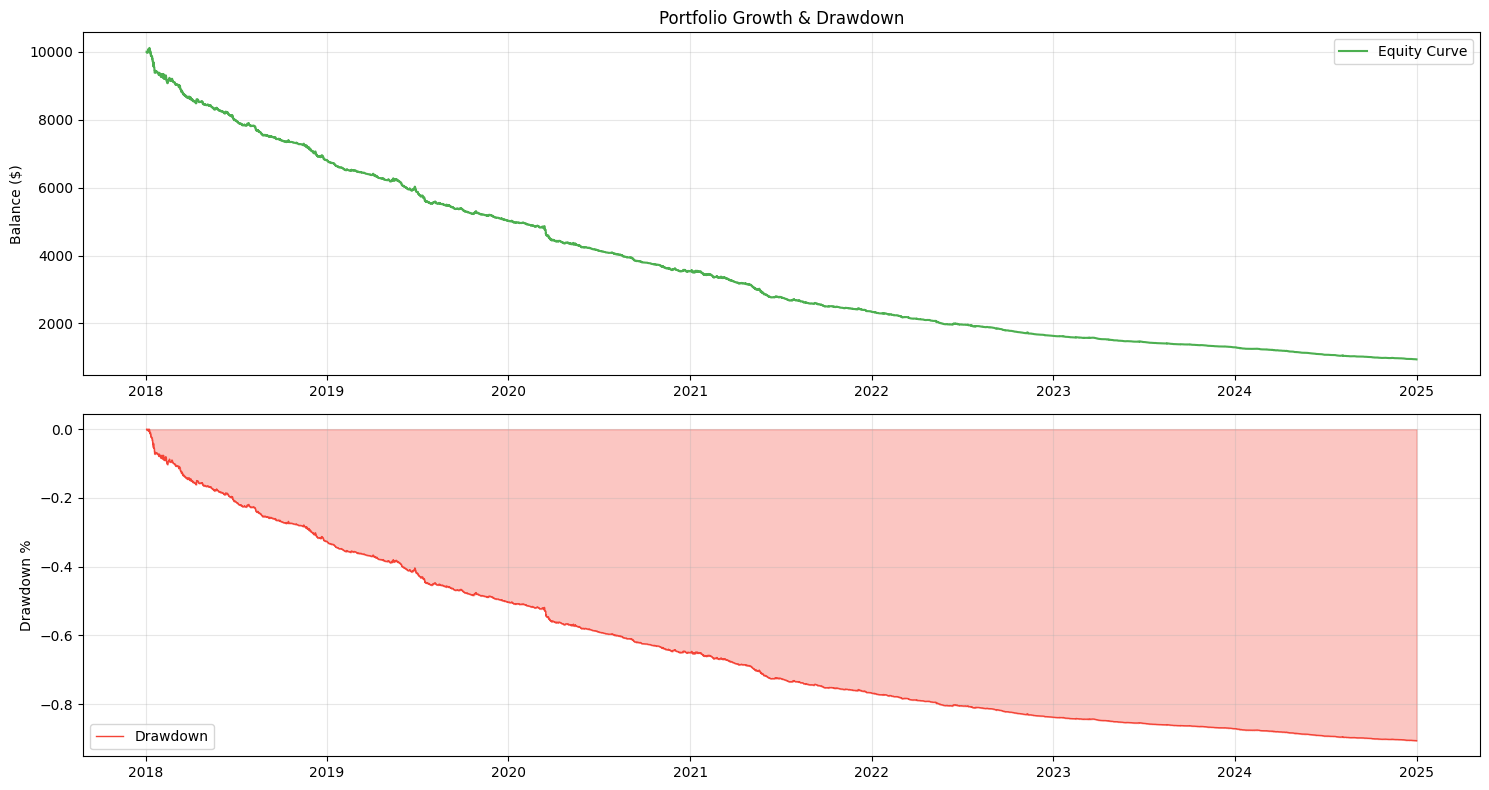

In [13]:
# ==============================================================================
# STEP 1: INSTALL LIBRARIES
# ==============================================================================
!pip install pandas_ta -q

import requests
import time
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ==============================================================================
# STEP 2: GLOBAL CONFIG
# ==============================================================================
CONFIG = {
    'SYMBOL': 'BTCUSDT',
    'INTERVAL': '1h',
    'START_DATE': '01/01/2018',
    'END_DATE': '31/12/2024',
    'INITIAL_CAPITAL': 10000.0,
    'POSITION_SIZE_PCT': 0.10,
    'FEE_RATE': 0.0004,
    'SLIPPAGE': 0.0002
}

# ==============================================================================
# MODULE 1: DATA HANDLER
# ==============================================================================
class BinanceDataFetcher:
    def __init__(self, symbol, interval, start_date, end_date):
        self.symbol = symbol.upper()
        self.interval = interval
        self.start_date = start_date
        self.end_date = end_date

    def _str_to_millis(self, date_str: str) -> int:
        dt = datetime.strptime(date_str, "%d/%m/%Y")
        return int(dt.timestamp() * 1000)

    def fetch(self) -> pd.DataFrame:
        base_url = "https://data-api.binance.vision"
        req_symbol = self.symbol

        print(f"Checking connection for {req_symbol}...")
        try:
            test = requests.get(f"{base_url}/api/v3/time", timeout=5)
            if test.status_code == 451:
                print("US IP detected. Switching to Binance.US...")
                base_url = "https://api.binance.us"
                if req_symbol == "BTCUSDT": req_symbol = "BTCUSD"
        except Exception:
            base_url = "https://api.binance.us"
            req_symbol = "BTCUSD"

        url = base_url + "/api/v3/klines"
        start_time = self._str_to_millis(self.start_date)

        if self.end_date == datetime.now().strftime("%d/%m/%Y"):
            end_time = int(time.time() * 1000)
        else:
            end_dt = datetime.strptime(self.end_date, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
            end_time = int(end_dt.timestamp() * 1000)

        all_klines =[]
        print(f"Downloading {req_symbol} ({self.interval})...")

        while start_time < end_time:
            params = {"symbol": req_symbol, "interval": self.interval, "startTime": start_time, "endTime": end_time, "limit": 1000}
            try:
                r = requests.get(url, params=params, timeout=10)
                if r.status_code != 200: break
                data = r.json()
                if not data: break
                all_klines.extend(data)
                start_time = data[-1][0] + 1
                time.sleep(0.05)
            except Exception: break

        if not all_klines: return pd.DataFrame()

        df = pd.DataFrame(all_klines, columns=["timestamp", "Open", "High", "Low", "Close", "Volume", "CT", "QAV", "NT", "TBBV", "TBQV", "I"])
        df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
        df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
        df.set_index("timestamp", inplace=True)
        df = df.astype(float)
        print(f"Total: {len(df)} candles fetched.")
        return df

# ==============================================================================
# MODULE 2: STRATEGY
# ==============================================================================
class TrendMomentumATRStrategy:
    def __init__(self):
        self.sma_fast = 9
        self.sma_slow = 50
        self.rsi_period = 14
        self.rsi_long_min = 40
        self.rsi_short_max = 60
        self.rsi_momentum = 3.0
        self.atr_period = 14
        self.atr_trail_mult = 2.0

    def calculate_indicators(self, df: pd.DataFrame) -> pd.DataFrame:
        df['SMA_Fast'] = ta.sma(df['Close'], length=self.sma_fast)
        df['SMA_Slow'] = ta.sma(df['Close'], length=self.sma_slow)
        df['RSI'] = ta.rsi(df['Close'], length=self.rsi_period)
        df['ATR'] = ta.atr(df['High'], df['Low'], df['Close'], length=self.atr_period)
        df.dropna(inplace=True)
        return df

# ==============================================================================
# MODULE 3: BACKTEST ENGINE (LONG & SHORT)
# ==============================================================================
class BacktestEngine:
    def __init__(self, df, strategy, config):
        self.df = strategy.calculate_indicators(df.copy())
        self.strategy = strategy
        self.config = config

        self.capital = config['INITIAL_CAPITAL']
        self.invested_amount = 0.0
        self.position = 0
        self.entry_price = 0.0
        self.trades =[]
        self.equity_curve = [self.capital] * len(self.df)
        self.extreme_price = 0.0
        self.trail_stop_price = 0.0

    def run(self):
        print("Running Backtest Engine (Long & Short)...")

        O = self.df['Open'].values; H = self.df['High'].values
        L = self.df['Low'].values; C = self.df['Close'].values
        times = self.df.index

        sma_f = self.df['SMA_Fast'].values; sma_s = self.df['SMA_Slow'].values
        rsi = self.df['RSI'].values; atr = self.df['ATR'].values

        fee = self.config['FEE_RATE']; slip = self.config['SLIPPAGE']
        pos_size_pct = self.config['POSITION_SIZE_PCT']
        atr_mult = self.strategy.atr_trail_mult

        for i in range(2, len(self.df)):
            if self.position != 0:
                exit_signal = False
                raw_exit_price = 0.0

                if self.position == 1:
                    if H[i] > self.extreme_price:
                        self.extreme_price = H[i]
                    current_trail = self.extreme_price - (atr_mult * atr[i-1])
                    if current_trail > self.trail_stop_price or self.trail_stop_price == 0:
                        self.trail_stop_price = current_trail
                    if L[i] <= self.trail_stop_price:
                        exit_signal = True
                        raw_exit_price = min(O[i], self.trail_stop_price)

                elif self.position == -1:
                    if L[i] < self.extreme_price:
                        self.extreme_price = L[i]
                    current_trail = self.extreme_price + (atr_mult * atr[i-1])
                    if current_trail < self.trail_stop_price or self.trail_stop_price == 0:
                        self.trail_stop_price = current_trail
                    if H[i] >= self.trail_stop_price:
                        exit_signal = True
                        raw_exit_price = max(O[i], self.trail_stop_price)

                if exit_signal:
                    if self.position == 1:
                        real_exit = raw_exit_price * (1 - slip)
                        pnl_pct = (real_exit - self.entry_price) / self.entry_price
                    else:
                        real_exit = raw_exit_price * (1 + slip)
                        pnl_pct = (self.entry_price - real_exit) / self.entry_price

                    net_pnl_pct = pnl_pct - (fee * 2)
                    pnl_amt = self.invested_amount * net_pnl_pct
                    self.capital += pnl_amt

                    self.trades.append({
                        'Date': times[i], 'Type': 'Long' if self.position == 1 else 'Short',
                        'Reason': f'ATR Trail ({atr_mult}x)',
                        'Entry': self.entry_price, 'Exit': real_exit,
                        'PnL_Amt': pnl_amt, 'Equity': self.capital
                    })
                    self.position = 0
                    self.trail_stop_price = 0.0
                    self.invested_amount = 0.0

            if self.position == 0:
                long_cond = (sma_f[i-1] > sma_s[i-1]) and (rsi[i-1] > self.strategy.rsi_long_min) and ((rsi[i-1] - rsi[i-2]) >= self.strategy.rsi_momentum)
                short_cond = (sma_f[i-1] < sma_s[i-1]) and (rsi[i-1] < self.strategy.rsi_short_max) and ((rsi[i-2] - rsi[i-1]) >= self.strategy.rsi_momentum)

                if long_cond:
                    self.position = 1
                    self.entry_price = O[i] * (1 + slip)
                    self.extreme_price = self.entry_price
                    self.trail_stop_price = self.extreme_price - (atr_mult * atr[i-1])
                    self.invested_amount = self.capital * pos_size_pct

                elif short_cond:
                    self.position = -1
                    self.entry_price = O[i] * (1 - slip)
                    self.extreme_price = self.entry_price
                    self.trail_stop_price = self.extreme_price + (atr_mult * atr[i-1])
                    self.invested_amount = self.capital * pos_size_pct

            self.equity_curve[i] = self.capital

        return pd.Series(self.equity_curve, index=self.df.index), pd.DataFrame(self.trades)

# ==============================================================================
# MODULE 4: PERFORMANCE EVALUATOR
# ==============================================================================
class Evaluator:
    @staticmethod
    def generate_report(equity, trades_df, initial_capital, symbol, pos_size_pct):
        if trades_df.empty:
            print("No trades executed!")
            return

        final_equity = equity.iloc[-1]
        net_pnl = final_equity - initial_capital
        total_return = net_pnl / initial_capital

        rolling_max = equity.cummax()
        drawdown = (equity - rolling_max) / rolling_max
        max_dd = drawdown.min()

        wins = trades_df[trades_df['PnL_Amt'] > 0]
        losses = trades_df[trades_df['PnL_Amt'] <= 0]
        winrate = len(wins) / len(trades_df) if len(trades_df) > 0 else 0
        profit_factor = wins['PnL_Amt'].sum() / abs(losses['PnL_Amt'].sum()) if len(losses) > 0 and losses['PnL_Amt'].sum() != 0 else 0

        days = (equity.index[-1] - equity.index[0]).days
        cagr = ((final_equity / initial_capital) ** (365.0 / days)) - 1 if days > 0 else 0

        returns = equity.pct_change().dropna()
        sharpe_ratio = (returns.mean() / returns.std()) * np.sqrt(365 * 24) if returns.std() != 0 else 0

        print(f"\n{'='*55}")
        print(f"PERFORMANCE REPORT: {symbol}")
        print(f"{'='*55}")
        print(f"{'Strategy:':>20} SMA/RSI + Dynamic ATR Trailing")
        print(f"{'Position Sizing:':>20} {pos_size_pct*100}% of Capital")
        print(f"{'Initial Capital:':>20} ${initial_capital:,.2f}")
        print(f"{'Final Equity:':>20} ${final_equity:,.2f}")
        print(f"{'Net PnL:':>20} ${net_pnl:,.2f}")
        print(f"{'Total Return:':>20} {total_return:.2%}")
        print(f"{'CAGR (Annual):':>20} {cagr:.2%}")
        print(f"{'Max Drawdown:':>20} {max_dd:.2%}")
        print(f"{'Sharpe Ratio:':>20} {sharpe_ratio:.2f}")
        print(f"{'Total Trades:':>20} {len(trades_df)}")
        print(f"{'Winrate:':>20} {winrate:.2%}")
        print(f"{'Profit Factor:':>20} {profit_factor:.2f}")
        print(f"{'='*55}")

        plt.figure(figsize=(15, 8))
        plt.subplot(2, 1, 1)
        plt.plot(equity, label='Equity Curve', color='#4CAF50', linewidth=1.5)
        plt.title('Portfolio Growth & Drawdown')
        plt.ylabel('Balance ($)')
        plt.grid(True, alpha=0.3); plt.legend()

        plt.subplot(2, 1, 2)
        plt.fill_between(drawdown.index, drawdown, 0, color='#F44336', alpha=0.3)
        plt.plot(drawdown, label='Drawdown', color='#F44336', linewidth=1)
        plt.ylabel('Drawdown %')
        plt.grid(True, alpha=0.3); plt.legend()
        plt.tight_layout()
        plt.show()

# ==============================================================================
# MAIN EXECUTION
# ==============================================================================
if __name__ == "__main__":
    fetcher = BinanceDataFetcher(CONFIG['SYMBOL'], CONFIG['INTERVAL'], CONFIG['START_DATE'], CONFIG['END_DATE'])
    df_raw = fetcher.fetch()

    if not df_raw.empty:
        my_strategy = TrendMomentumATRStrategy()
        engine = BacktestEngine(df_raw, my_strategy, CONFIG)
        equity, trades = engine.run()
        Evaluator.generate_report(equity, trades, CONFIG['INITIAL_CAPITAL'], CONFIG['SYMBOL'], CONFIG['POSITION_SIZE_PCT'])

Checking connection for BTCUSDT...
Total: 28587 candles fetched.
Running Backtest Engine (Short Only)...

PERFORMANCE REPORT: BTCUSDT
           Strategy: SMA/RSI + Dynamic ATR Trailing
    Position Sizing: 10.0% of Capital
    Initial Capital: $10,000.00
       Final Equity: $6,071.87
            Net PnL: $-3,928.13
       Total Return: -39.28%
      CAGR (Annual): -14.20%
       Max Drawdown: -39.28%
       Sharpe Ratio: -6.77
       Total Trades: 1293
            Winrate: 29.62%
      Profit Factor: 0.37


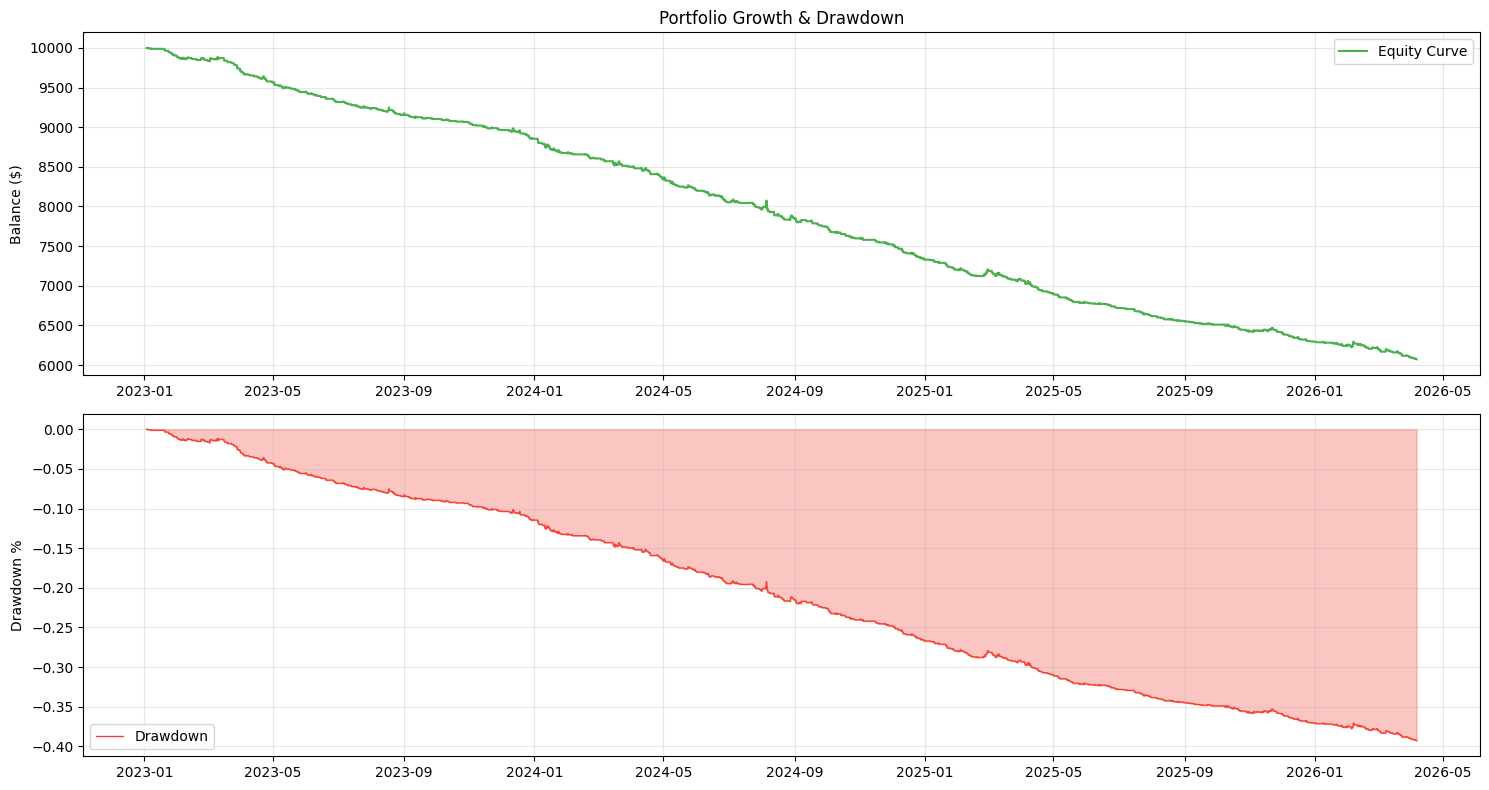

In [12]:
# ==============================================================================
# STEP 1: INSTALL LIBRARIES
# ==============================================================================
!pip install pandas_ta -q

import requests
import time
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ==============================================================================
# STEP 2: GLOBAL CONFIG
# ==============================================================================
CONFIG = {
    'SYMBOL': 'BTCUSDT',
    'INTERVAL': '1h',
    'START_DATE': '01/01/2023',
    'END_DATE': '31/12/2026',
    'INITIAL_CAPITAL': 10000.0,
    'POSITION_SIZE_PCT': 0.10,
    'FEE_RATE': 0.0004,
    'SLIPPAGE': 0.0002
}

# ==============================================================================
# MODULE 1: DATA HANDLER
# ==============================================================================
class BinanceDataFetcher:
    def __init__(self, symbol, interval, start_date, end_date):
        self.symbol = symbol.upper()
        self.interval = interval
        self.start_date = start_date
        self.end_date = end_date

    def _str_to_millis(self, date_str: str) -> int:
        dt = datetime.strptime(date_str, "%d/%m/%Y")
        return int(dt.timestamp() * 1000)

    def fetch(self) -> pd.DataFrame:
        base_url = "https://data-api.binance.vision"
        req_symbol = self.symbol

        print(f"Checking connection for {req_symbol}...")
        try:
            test = requests.get(f"{base_url}/api/v3/time", timeout=5)
            if test.status_code == 451:
                print("US IP detected. Switching to Binance.US...")
                base_url = "https://api.binance.us"
                if req_symbol == "BTCUSDT": req_symbol = "BTCUSD"
        except Exception:
            base_url = "https://api.binance.us"
            req_symbol = "BTCUSD"

        url = base_url + "/api/v3/klines"
        start_time = self._str_to_millis(self.start_date)

        if self.end_date == datetime.now().strftime("%d/%m/%Y"):
            end_time = int(time.time() * 1000)
        else:
            end_dt = datetime.strptime(self.end_date, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
            end_time = int(end_dt.timestamp() * 1000)

        all_klines =[]
        print(f"Downloading {req_symbol} ({self.interval})...")

        while start_time < end_time:
            params = {"symbol": req_symbol, "interval": self.interval, "startTime": start_time, "endTime": end_time, "limit": 1000}
            try:
                r = requests.get(url, params=params, timeout=10)
                if r.status_code != 200: break
                data = r.json()
                if not data: break
                all_klines.extend(data)
                start_time = data[-1][0] + 1
                time.sleep(0.05)
            except Exception: break

        if not all_klines: return pd.DataFrame()

        df = pd.DataFrame(all_klines, columns=["timestamp", "Open", "High", "Low", "Close", "Volume", "CT", "QAV", "NT", "TBBV", "TBQV", "I"])
        df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
        df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
        df.set_index("timestamp", inplace=True)
        df = df.astype(float)
        print(f"Total: {len(df)} candles fetched.")
        return df

# ==============================================================================
# MODULE 2: STRATEGY
# ==============================================================================
class TrendMomentumATRStrategy:
    def __init__(self):
        self.sma_fast = 9
        self.sma_slow = 50
        self.rsi_period = 14
        self.rsi_long_min = 40
        self.rsi_short_max = 60
        self.rsi_momentum = 3.0
        self.atr_period = 14
        self.atr_trail_mult = 2.0

    def calculate_indicators(self, df: pd.DataFrame) -> pd.DataFrame:
        df['SMA_Fast'] = ta.sma(df['Close'], length=self.sma_fast)
        df['SMA_Slow'] = ta.sma(df['Close'], length=self.sma_slow)
        df['RSI'] = ta.rsi(df['Close'], length=self.rsi_period)
        df['ATR'] = ta.atr(df['High'], df['Low'], df['Close'], length=self.atr_period)
        df.dropna(inplace=True)
        return df

# ==============================================================================
# MODULE 3: BACKTEST ENGINE (LONG & SHORT)
# ==============================================================================
class BacktestEngine:
    def __init__(self, df, strategy, config):
        self.df = strategy.calculate_indicators(df.copy())
        self.strategy = strategy
        self.config = config

        self.capital = config['INITIAL_CAPITAL']
        self.invested_amount = 0.0
        self.position = 0
        self.entry_price = 0.0
        self.trades =[]
        self.equity_curve = [self.capital] * len(self.df)
        self.extreme_price = 0.0
        self.trail_stop_price = 0.0

    def run(self):
        print("Running Backtest Engine (Long & Short)...")

        O = self.df['Open'].values; H = self.df['High'].values
        L = self.df['Low'].values; C = self.df['Close'].values
        times = self.df.index

        sma_f = self.df['SMA_Fast'].values; sma_s = self.df['SMA_Slow'].values
        rsi = self.df['RSI'].values; atr = self.df['ATR'].values

        fee = self.config['FEE_RATE']; slip = self.config['SLIPPAGE']
        pos_size_pct = self.config['POSITION_SIZE_PCT']
        atr_mult = self.strategy.atr_trail_mult

        for i in range(2, len(self.df)):
            if self.position != 0:
                exit_signal = False
                raw_exit_price = 0.0

                if self.position == 1:
                    if H[i] > self.extreme_price:
                        self.extreme_price = H[i]
                    current_trail = self.extreme_price - (atr_mult * atr[i-1])
                    if current_trail > self.trail_stop_price or self.trail_stop_price == 0:
                        self.trail_stop_price = current_trail
                    if L[i] <= self.trail_stop_price:
                        exit_signal = True
                        raw_exit_price = min(O[i], self.trail_stop_price)

                elif self.position == -1:
                    if L[i] < self.extreme_price:
                        self.extreme_price = L[i]
                    current_trail = self.extreme_price + (atr_mult * atr[i-1])
                    if current_trail < self.trail_stop_price or self.trail_stop_price == 0:
                        self.trail_stop_price = current_trail
                    if H[i] >= self.trail_stop_price:
                        exit_signal = True
                        raw_exit_price = max(O[i], self.trail_stop_price)

                if exit_signal:
                    if self.position == 1:
                        real_exit = raw_exit_price * (1 - slip)
                        pnl_pct = (real_exit - self.entry_price) / self.entry_price
                    else:
                        real_exit = raw_exit_price * (1 + slip)
                        pnl_pct = (self.entry_price - real_exit) / self.entry_price

                    net_pnl_pct = pnl_pct - (fee * 2)
                    pnl_amt = self.invested_amount * net_pnl_pct
                    self.capital += pnl_amt

                    self.trades.append({
                        'Date': times[i], 'Type': 'Long' if self.position == 1 else 'Short',
                        'Reason': f'ATR Trail ({atr_mult}x)',
                        'Entry': self.entry_price, 'Exit': real_exit,
                        'PnL_Amt': pnl_amt, 'Equity': self.capital
                    })
                    self.position = 0
                    self.trail_stop_price = 0.0
                    self.invested_amount = 0.0

            if self.position == 0:
                long_cond = (sma_f[i-1] > sma_s[i-1]) and (rsi[i-1] > self.strategy.rsi_long_min) and ((rsi[i-1] - rsi[i-2]) >= self.strategy.rsi_momentum)
                short_cond = (sma_f[i-1] < sma_s[i-1]) and (rsi[i-1] < self.strategy.rsi_short_max) and ((rsi[i-2] - rsi[i-1]) >= self.strategy.rsi_momentum)

                if long_cond:
                    self.position = 1
                    self.entry_price = O[i] * (1 + slip)
                    self.extreme_price = self.entry_price
                    self.trail_stop_price = self.extreme_price - (atr_mult * atr[i-1])
                    self.invested_amount = self.capital * pos_size_pct

                elif short_cond:
                    self.position = -1
                    self.entry_price = O[i] * (1 - slip)
                    self.extreme_price = self.entry_price
                    self.trail_stop_price = self.extreme_price + (atr_mult * atr[i-1])
                    self.invested_amount = self.capital * pos_size_pct

            self.equity_curve[i] = self.capital

        return pd.Series(self.equity_curve, index=self.df.index), pd.DataFrame(self.trades)

# ==============================================================================
# MODULE 4: PERFORMANCE EVALUATOR
# ==============================================================================
class Evaluator:
    @staticmethod
    def generate_report(equity, trades_df, initial_capital, symbol, pos_size_pct):
        if trades_df.empty:
            print("No trades executed!")
            return

        final_equity = equity.iloc[-1]
        net_pnl = final_equity - initial_capital
        total_return = net_pnl / initial_capital

        rolling_max = equity.cummax()
        drawdown = (equity - rolling_max) / rolling_max
        max_dd = drawdown.min()

        wins = trades_df[trades_df['PnL_Amt'] > 0]
        losses = trades_df[trades_df['PnL_Amt'] <= 0]
        winrate = len(wins) / len(trades_df) if len(trades_df) > 0 else 0
        profit_factor = wins['PnL_Amt'].sum() / abs(losses['PnL_Amt'].sum()) if len(losses) > 0 and losses['PnL_Amt'].sum() != 0 else 0

        days = (equity.index[-1] - equity.index[0]).days
        cagr = ((final_equity / initial_capital) ** (365.0 / days)) - 1 if days > 0 else 0

        returns = equity.pct_change().dropna()
        sharpe_ratio = (returns.mean() / returns.std()) * np.sqrt(365 * 24) if returns.std() != 0 else 0

        print(f"\n{'='*55}")
        print(f"PERFORMANCE REPORT: {symbol}")
        print(f"{'='*55}")
        print(f"{'Strategy:':>20} SMA/RSI + Dynamic ATR Trailing")
        print(f"{'Position Sizing:':>20} {pos_size_pct*100}% of Capital")
        print(f"{'Initial Capital:':>20} ${initial_capital:,.2f}")
        print(f"{'Final Equity:':>20} ${final_equity:,.2f}")
        print(f"{'Net PnL:':>20} ${net_pnl:,.2f}")
        print(f"{'Total Return:':>20} {total_return:.2%}")
        print(f"{'CAGR (Annual):':>20} {cagr:.2%}")
        print(f"{'Max Drawdown:':>20} {max_dd:.2%}")
        print(f"{'Sharpe Ratio:':>20} {sharpe_ratio:.2f}")
        print(f"{'Total Trades:':>20} {len(trades_df)}")
        print(f"{'Winrate:':>20} {winrate:.2%}")
        print(f"{'Profit Factor:':>20} {profit_factor:.2f}")
        print(f"{'='*55}")

        plt.figure(figsize=(15, 8))
        plt.subplot(2, 1, 1)
        plt.plot(equity, label='Equity Curve', color='#4CAF50', linewidth=1.5)
        plt.title('Portfolio Growth & Drawdown')
        plt.ylabel('Balance ($)')
        plt.grid(True, alpha=0.3); plt.legend()

        plt.subplot(2, 1, 2)
        plt.fill_between(drawdown.index, drawdown, 0, color='#F44336', alpha=0.3)
        plt.plot(drawdown, label='Drawdown', color='#F44336', linewidth=1)
        plt.ylabel('Drawdown %')
        plt.grid(True, alpha=0.3); plt.legend()
        plt.tight_layout()
        plt.show()

# ==============================================================================
# MAIN EXECUTION
# ==============================================================================
if __name__ == "__main__":
    fetcher = BinanceDataFetcher(CONFIG['SYMBOL'], CONFIG['INTERVAL'], CONFIG['START_DATE'], CONFIG['END_DATE'])
    df_raw = fetcher.fetch()

    if not df_raw.empty:
        my_strategy = TrendMomentumATRStrategy()
        engine = BacktestEngine(df_raw, my_strategy, CONFIG)
        equity, trades = engine.run()
        Evaluator.generate_report(equity, trades, CONFIG['INITIAL_CAPITAL'], CONFIG['SYMBOL'], CONFIG['POSITION_SIZE_PCT'])